
<a href="https://colab.research.google.com/github/CienciaDatosUdea/002_EstudiantesAprendizajeEstadistico/blob/main/semestre2026-2/Laboratorios/Laboratorio_08_nn_zeroV1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>




In [61]:
import pandas as pd
import scipy as sc
import numpy as np
import h5py
import matplotlib.pylab as plt

In [62]:
data_train= "../../Laboratorios/datasets/cat_not_cat/train_catvnoncat.h5"
train_dataset = h5py.File(data_train, "r")

data_test= "../../Laboratorios/datasets/cat_not_cat/test_catvnoncat.h5"
test_dataset = h5py.File(data_test, "r")

In [63]:
train_dataset.keys()

<KeysViewHDF5 ['list_classes', 'train_set_x', 'train_set_y']>

In [64]:
# Read the data
xtrain_classes, xtrain, train_label =\
train_dataset["list_classes"],train_dataset["train_set_x"],train_dataset["train_set_y"]

test_classes, xtest,test_label =\
test_dataset["list_classes"],test_dataset["test_set_x"],test_dataset["test_set_y"]


In [65]:
np.shape(xtrain)

(209, 64, 64, 3)

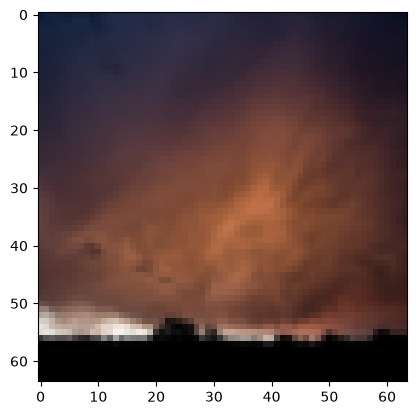

In [66]:
plt.imshow(xtrain[208])

In [67]:
np.shape(xtrain[0])

(64, 64, 3)

In [68]:
np.reshape(xtrain[0], 64*64*3)

array([17, 31, 56, ...,  0,  0,  0], shape=(12288,), dtype=uint8)

In [69]:

xtrain_= np.reshape(xtrain,(209, 64*64*3))/255
xtest_ = np.reshape(xtest,(50, 64*64*3))/255

In [70]:
len(xtrain_[208])

12288

In [71]:
64*64*3

12288

In [108]:
#CLASE 13-10-2026

def act_function(name, x):
    if name == 'sigmoid':
        f = lambda x: 1/(1 + np.exp(-x))
        fp = f(x) * (1 - f(x))
        return np.array([f(x), fp])
    else:
        raise ValueError("Función de activación no definida")
    

class layer():
    """
    Esta clase representa una capa de una red neuronal.
    Contiene los pesos y el sesgo de la capa, así como
    un método para calcular la salida de la capa dado un
    conjunto de entradas.
    """
    def __init__(self, nL, nL_l, name):
        # Inicializa los parametros theta y B de la capa con valores aleatorios
        self.theta = 2 * np.random.random((nL, nL_l)) - 1
        self.B = 2 * np.random.random((nL, 1)) - 1
        # Almacena el nombre de la función de activación
        self.name = name 

    def output(self, X):
        """
        Calcula la salida de la capa dado un conjunto de entradas A.
        La salida se calcula como Z = theta * A + B, y luego se aplica
        la función de activación.
        """
        # Calcula la salida de la capa
        self.Z = self.theta @ X + self.B
        # Aplica la función de activación a la salida
        F = act_function(self.name, self.Z)
        # Almacena la salida de la capa y su derivada
        self.A = F[0]
        self.Ap = F[1]

    def update_params(self, dtheta):
        self.theta = dtheta
        


In [109]:
# Probemos la clase layer con una capa de 3 neuronas y 4 entradas
nn = layer(3, 4, 'sigmoid')

# Probemos la salida de la capa con una entrada aleatoria
A = np.random.random((4, 1))
nn.output(A)

In [110]:
#Realizemos un forward pass 

#Definimos una entrada aleatoria de 4 neuronas y 1 entrada
input_neurons, input_samples = 4, 1
Ainput = np.random.random((input_neurons, input_samples))

#Creamos una capa con 3 neuronas y 4 entradas, con función de activación sigmoide (Capa de entrada)
nn0 = layer(3, 4, 'sigmoid')
#Calculamos la salida de la capa nn0 con la entrada Ainput
nn0.output(Ainput)

#FORWARD PASS: Aplicamos la salida de la capa nn0 como entrada de la capa nn1 y asi
# sucesivamente hasta la capa de salida.

#Creamos una capa con 2 neuronas y 3 entradas, con función de activación sigmoide (Capa oculta)
nn1 = layer(2, 3, 'sigmoid')
#Calculamos la salida de la capa nn1 con la salida de la capa nn0 como entrada
nn1.output(nn0.A)

#Capa Oculta 2
nn2 = layer(5, 2, 'sigmoid')
nn2.output(nn1.A)

#Capa de salida
nn3 = layer(1, 5, 'sigmoid')
nn3.output(nn2.A)

print("Finalmente imprimimos la salida de la capa de salida")
print("Esto es la predicción de la red neuronal para la entrada Ainput\n")
print(nn3.A)

print("\nImprimimos la salida de la capa oculta\n")
print(nn2.Z)

Topology = [4, 3, 2, 5, 1]

print("\nTopología de la red neuronal\n")
print(Topology)

Finalmente imprimimos la salida de la capa de salida
Esto es la predicción de la red neuronal para la entrada Ainput

[[0.57508571]]

Imprimimos la salida de la capa oculta

[[ 0.31074213]
 [-1.36416567]
 [-0.29487639]
 [ 1.40622298]
 [-0.71064616]]

Topología de la red neuronal

[4, 3, 2, 5, 1]


In [111]:
#Automatizando el forward pass anterior

red = []

#Recorremos la topología de la red neuronal y creamos las capas correspondientes
for i in range(0, len(Topology)-1):
    nn = layer(Topology[i+1], Topology[i], 'sigmoid')
    red.append(nn)

#Usemos Ainput anterior como entrada de la red neuronal y calculemos la salida de cada capa

#Forward
Ainput = np.random.random((4, 3))
#Calculamos la salida de la primera capa con la entrada Ainput
red[0].output(Ainput)

#Calculamos la salida de las capas ocultas y de salida con la salida de la capa anterior como entrada
for i in range(1, len(Topology)-1):
    red[i].output(red[i-1].A)

print("Finalmente imprimimos la salida de la capa de salida")
print("Esto es la predicción de la red neuronal para la entrada Ainput\n")
print(red[-1].A)

Finalmente imprimimos la salida de la capa de salida
Esto es la predicción de la red neuronal para la entrada Ainput

[[0.67143442 0.67272334 0.67353069]]


In [112]:
#CLASE 15-10-2026

#Forward
Ainput = np.random.random((4, 3))

#Agregamos y_esperado como salida de la red neuronal para la entrada Ainput
y_esperado = np.random.randint(2, size=(1, 3))

#Calculamos la salida de la primera capa con la entrada Ainput
red[0].output(Ainput)

#Calculamos la salida de las capas ocultas y de salida con la salida de la capa anterior como entrada
for i in range(1, len(Topology)-1):
    red[i].output(red[i-1].A)

print("Finalmente imprimimos la salida de la capa de salida")
print("Esto es la predicción de la red neuronal para la entrada Ainput\n")

Al = red[-1].A

print(Al)
print("Y esto es el valor esperado\n")
print(y_esperado)

Finalmente imprimimos la salida de la capa de salida
Esto es la predicción de la red neuronal para la entrada Ainput

[[0.67227258 0.67392874 0.67316438]]
Y esto es el valor esperado

[[1 0 0]]


In [113]:
#Computemos ahora la funcion de coste con cross-entropy para la salida de la red neuronal y el valor esperado

def FuncionCoste(y_esperado, Al):
    """
    Calcula la función de coste J utilizando la fórmula de cross-entropy.
    
    Parámetros:
    y_esperado -- array de valores esperados (etiquetas verdaderas)
    Al -- array de salidas de la red neuronal (predicciones)
    
    Retorna:
    J_coste -- valor escalar de la función de coste
    """

    J = y_esperado * np.log(Al) + (1 - y_esperado) * np.log(1 - Al)
    J_coste = J.mean()  # Normalizamos por el número de ejemplos para obtener un valor escalar
    
    return J_coste

J_coste = FuncionCoste(y_esperado, Al)
print("La función de coste J es: ", J_coste)
print("Esto es un valor escalar que representa la diferencia entre la salida de la red neuronal y el valor esperado\n" \
"deberia ser cercano a 0 si la red neuronal está bien entrenada")

La función de coste J es:  -0.8786762180262567
Esto es un valor escalar que representa la diferencia entre la salida de la red neuronal y el valor esperado
deberia ser cercano a 0 si la red neuronal está bien entrenada


In [114]:
np.random.seed(0)

#Ahora hagamos el forward pass con el dataset de imagenes de gatos y no gatos
    
Ainput = xtrain_.T

# Nuestro y_esperado es el vector de etiquetas de entrenamiento,
# que indica si cada imagen es un gato (1) o no (0)
y_esperado = np.reshape(train_label, (train_label.shape[0], 1))

#Definimos la topología de la red neuronal para este dataset
l_input = len(Ainput)
Topology = [l_input, 3, 2, 5, 1]
L = len(Topology)

red = []

#Recorremos la topología de la red neuronal y creamos las capas correspondientes
for i in range(0, len(Topology)-1):
    nn = layer(Topology[i+1], Topology[i], 'sigmoid')
    red.append(nn)


print(f"Los tamaños de Ainput y y_esperado son: A_input: {Ainput.shape}, y_esperado: {y_esperado.shape}")
print(f"Los tamaños de las capas de la red neuronal son: {red[0].theta.shape}, {red[0].B.shape}")
print(f"La topología de la red neuronal es: {Topology}")
print(f"El número de capas en la red neuronal es: {L}")

#forward pass con el dataset de imagenes de gatos y no gatos
red[0].output(Ainput)
for i in range(1, L-1):
    red[i].output(red[i-1].A)

#Salida de la red neuronal
Al = red[-1].A

print("\nFinalmente imprimimos la salida de la capa de salida")
print("Esto es la predicción de la red neuronal para la entrada Ainput\n")

print(f"El tamaño de la salida de la red neuronal es: {Al.shape}")
print(Al)



Los tamaños de Ainput y y_esperado son: A_input: (12288, 209), y_esperado: (209, 1)
Los tamaños de las capas de la red neuronal son: (3, 12288), (3, 1)
La topología de la red neuronal es: [12288, 3, 2, 5, 1]
El número de capas en la red neuronal es: 5

Finalmente imprimimos la salida de la capa de salida
Esto es la predicción de la red neuronal para la entrada Ainput

El tamaño de la salida de la red neuronal es: (1, 209)
[[0.76134982 0.75965558 0.75972405 0.76176359 0.76674631 0.76175802
  0.76176347 0.76087766 0.76176359 0.75965431 0.76176359 0.76174444
  0.75965463 0.75965442 0.75965431 0.76130757 0.76176346 0.75966275
  0.76155863 0.7605338  0.75969486 0.76174538 0.75965431 0.76176359
  0.7596787  0.76173762 0.75965432 0.761611   0.75981921 0.76176355
  0.76177121 0.75965473 0.75965431 0.76165677 0.76674602 0.76635998
  0.75965431 0.75965431 0.76769349 0.75965432 0.75965431 0.76676375
  0.76176293 0.75965431 0.76171455 0.76138883 0.76176359 0.76081198
  0.75965771 0.75965431 0.7596

In [115]:
#Ahora la funcion de coste 
J_coste = FuncionCoste(y_esperado, Al)
print("La función de coste J es: ", J_coste)

La función de coste J es:  -1.0318988131348266


In [ ]:
#Ahora implementaremos el Backward pass para actualizar los pesos y sesgos de la red neuronal

#PARA LA ULTIMA CAPA DE LA RED NEURONAL (CAPA DE SALIDA)

L_final = len(Topology) - 2  # Índice de la capa no oculta final (capa de salida)

#Implementamos las derivadas implicitas
dAL = -(np.divide(y_esperado, Al) - np.divide(1 - y_esperado, 1 - Al))

#Tomamos la derivada de la función de activación de la capa de salida
fp = red[L_final].Ap

dZL = dAL * fp
dtheta = dZL @ red[L_final - 1].A.T

#Actualizamos los parámetros de la capa de salida
red[L_final].update_params(dtheta)

Construyamos una red neuronal con una capa de entrada, una capa de salida con una red y L-1 redes ocultas.

# Con m datos de entrenamientos.

Para $m$ datos de entrenamiento, las expresión anteriores pueden ser resumidas en las siguientes ecuaciones



\begin{equation}
\begin{bmatrix}
z_1^{(0)}  &z_1^{(1)} & .&.& .&z_1^{(m)}\\
z_2^{(0)}  &z_2^{(1)} &. &.&  .&z_2^{(m)}\\
.          & .        &. & &   &.      \\
.          & .        &  &. &   &.      \\
.          & .        &  &  & .&      \\
z_{n^{[l]}}^{(0)}&z_{n^{[l]}}^{(1)} & . & .& .& z_{n^{[l]}}^{(m)}        \\
\end{bmatrix}^{[l]}=
\begin{bmatrix}
\theta_{11} & \theta_{12} & . & .& .& \theta_{1n^{[l-1]}}\\
\theta_{21} & \theta_{22} & . & .& .& \theta_{2n^{[l-1]}}\\
. & .  & . &   & & .\\
. & .  &   & . & & .\\
. & .  &   &  & .& .\\
\theta_{n^{[l]}1} & \theta_{n^{[l]}2} & . & .& .& \theta_{n^{[l]}n^{[l-1]}}\\
\end{bmatrix}^{[l]}_{n^{[l]} \times n^{[l-1]}}
\begin{bmatrix}
a_1^{(0)}  &a_1^{(1)} & .&.& .&a_1^{(m)}\\
a_2^{(0)}  &a_2^{(1)} &. &.&  .&a_2^{(m)}\\
.          & .        &. & &   &.      \\
.          & .        &  &. &   &.      \\
.          & .        &  &  & .&      \\
a_{n^{[L-1]}}^{(0)}&a_{n^{[L-1]}}^{(1)} & . & .& .& a_{n^{[L-1]}}^{(m)}        \\
\end{bmatrix}^{[l-1]} +
\begin{bmatrix}
b_1 \\
b_2 \\
. \\
. \\
. \\
b_{n^{[l]}}\\
\end{bmatrix}^{[l]}
\end{equation}


Escrito de una formas mas compacta tenemos que:


\begin{equation}
[ \vec{Z}^{[l](0)},\vec{Z}^{[l](1)},...,\vec{Z}^{[l](m)}  ]= \Theta^{[l]} [\vec{A}^{[l-1](0)},\vec{A}^{[l-1](1)},...,\vec{A}^{[l-1](m)} ]+ \vec{b}^{[l]}
\end{equation}

Aplicando la funcion de activación:

\begin{equation}
[\vec{A}^{[l](0)},\vec{A}^{[l](1)},...,\vec{A}^{[l](m)} ]=f([\vec{Z}^{[l](0)},\vec{Z}^{[l](1)},...,\vec{Z}^{[l](m)}  ])
\end{equation}

Las dimensiones de las expresiones anteriores, pueden ser resumidas en lo siguiente:

$\mathrm{dim(\vec{\cal{Z}}^{[l]})}=n^{[l]}\times m $

$\mathrm{dim(\vec{\Theta}^{[l]})}=n^{[l]}\times n^{[l-1]}$

$\mathrm{dim(\vec{\cal{A}}^{[l]})}=n^{[l-1]}\times m $

$\mathrm{dim(\vec{b}^{[l]})}=n^{[l]}$




## Topología de la red.

1. Construir un clase  que permita definir una red neuronal con la topología
deseada y la función de activación para cada capa, para ello deberá construir una funcion Topology con el número de capas de la red neuronal :

Topology = [n_x, n_h1, n_h2, n_h3, ...,n_y]

En este caso:
- $n^{[0]}=n_x$ seran los valores de entradas de la capa de entrada
- $n^{[1]}=n_{h1}$ Primera capa oculta de la red neuronal
- $n^{[2]}=n_{h2}$ Segunda capa oculta de la red neuronal

.

.

.


- $n^{[l]}=n_{hl}$ Segunda capa oculta de la red neuronal
.

.

.

- $n^{[L]}=n_{y}$ Segunda capa oculta de la red neuronal

donde

- $\mathrm{n_x}$: valores de entrada
- $\mathrm{n_{h1}}$: hidden layer 1
- $\mathrm{n_{h2}}$: hidden layer 2
- $\mathrm{n_y}$: last layer

- $n^{[L]}=n_{y}$ Segunda capa oculta de la red neuronal


También definir una lista con las funciones de activaciones para cada capa.


activation=[None, relu, relu, relu, ...,sigmoid]

  


a. Cada unas de las capas deberá tener los parámetros de inicialización de manera aleatoria:


La matriz de parametros para cada capa debera tener:


$\mathrm{dim(\vec{b}^{[l]})}=n^{[l]}$

$\mathrm{dim(\vec{\Theta}^{[l]})}=n^{[l]}\times n^{[l-1]}$

Lo anteriores parametros deberán estar en el constructor de la clase.


b. Construya un metodo llamado output cuya salida serán los valores de Z y A


$\mathrm{dim(\vec{\cal{A}}^{[l]})}=n^{[l-1]}\times m $

$\mathrm{dim(\vec{\cal{Z}}^{[l]})}=n^{[l]}\times m $.

In [19]:
import numpy as np
class layer_nn():
    def __init__(self, act_fun, nlayer_presente, nlayer_before):
        self.theta = 2*np.random.random((nlayer_presente, nlayer_before))-1
        self.B = 2*np.random.random((nlayer_presente, 1))-1
        self.act_fun = act_fun
        

In [20]:
def act_funcion(x, activation):
    if activation=="sigmoid":
        f=lambda x: 1/(1+np.exp(-x))
        fp=f(x)*(1-f(x))
        return np.array([f, fp])
  

In [21]:
layer = layer_nn("sigmoid", 3, 3)

In [22]:
topology = [10, 3, 4, 6, 1]
l1 = layer_nn("sigmoid", 3, 10)
l2 = layer_nn("sigmoid", 4, 3)
l3 = layer_nn("sigmoid", 6, 4)
l4 = layer_nn("sigmoid", 1, 6)


In [23]:
A0 = xtrain_.T

In [24]:
Z1 = l1.theta.T@A0+l1.B

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 12288 is different from 3)



Se sugiere para cada capa emplear programación orientada a objetos definida de la siguiente manera:

```
class layer_nn():
  def __init__(self, act_fun, nlayer_present, nlayer_before):
    self.theta = 2*np.random.random((nlayer_present, nlayer_before)) - 1
    self.B = 2*np.random.random((nlayer_present,1)) - 1
    self.act_fun = act_fun

  def output(self, Z, A):
    self.Z = Z
    self.A = A



def act_function(x, activation):
  if activation=="sigmoid":
    f = lambda x: 1/(1+np.exp(-x))
    fp = f(x)*(1-f(x))
    return f, fp
  
  elif activation == "tanh":
    f = lambda x: np.tanh
    return tanh
  else :
    return 0
```
    

2. Construir un generalizacion de la red, en el que entrada el valor inicial
y la red neuronal completa arroje la salida y la actualizacion de la red con los parametros deseados:

  ```
  A, nn = forward_pass(A0, nn_red)

 ```
3. Encontrar la funcion de coste.


$$-\frac{1}{m} \sum\limits_{i = 1}^{m} (y^{(i)}\log\left(a^{[L] (i)}\right) + (1-y^{(i)})\log\left(1- a^{[L](i)}\right)) \tag{7}$$


4. Construir un codigo que permita realizar el BackwardPropagation


# Backward Propagation

Para una capa $l$ arbitraria tenemos que:

- \begin{equation}
d\Theta^{[l]} =  d{\cal Z}^{(i)[l]} Trans(A)^{(i)[l-1]} = dA^{(i)[l]} f'({\cal Z}^{(i)[l]} ) Trans(A)^{(i)[l-1]}
\end{equation}

- \begin{equation}
db^{[l]} =  d{\cal Z}^{(i)[L]}  = dA^{(i)[l]} f'({\cal Z}^{(i)[l]} )
\end{equation}
```
db_L =  m_*np.sum(dZ, axis=1, keepdims=True)
```
Los valores de dA pueden ser escritos como:
- \begin{equation}
dA^{(i)[l-1]} = \Theta^{l} \cdot dZ^{(i)[l]}
\end{equation}





$ dZ^{[l]} = dA^{[l]} * f'^{[l]} (Z^{[l]}) $
$ d\Theta^{[l]} = \frac{\partial \mathcal{J} }{\partial \Theta^{[l]}} = \frac{1}{m} dZ^{[l]} A^{[l-1] T} \tag{1}$
$ db^{[l]} = \frac{\partial \mathcal{J} }{\partial b^{[l]}} = \frac{1}{m} \sum_{i = 1}^{m} dZ^{[l](i)}\tag{2}$
$ dA^{[l-1]} = \frac{\partial \mathcal{L} }{\partial A^{[l-1]}} = \theta^{[l] T} dZ^{[l]} \tag{3}$


Para la capa L esima:

```
dAL = -(np.divide(Y, A) - np.divide(1 - Y, 1 - A))
```

# Aplicacion gradiente descendente

$$ \Theta^{[l]} = \Theta^{[l]} - \alpha \text{ } d\Theta^{[l]} \tag{16}$$
$$ b^{[l]} = b^{[l]} - \alpha \text{ } db^{[l]} \tag{17}$$


# Generalizacion Forward Pass


\begin{equation}
[ \vec{Z}^{[l](0)},\vec{Z}^{[l](1)},...,\vec{Z}^{[l](m)}  ]= \Theta^{[l]} [\vec{A}^{[l-1](0)},\vec{A}^{[l-1](1)},...,\vec{A}^{[l-1](m)} ]+ \vec{b}^{[l]}
\end{equation}




# Backward Propagation

Para una capa $l$ arbitraria tenemos que:

- \begin{equation}
d\Theta^{[l]} =  d{\cal Z}^{(i)[l]} Trans(A)^{(i)[l-1]} = dA^{(i)[l]} f'({\cal Z}^{(i)[l]} ) Trans(A)^{(i)[l-1]}
\end{equation}

- \begin{equation}
db^{[l]} =  d{\cal Z}^{(i)[L]}  = dA^{(i)[l]} f'({\cal Z}^{(i)[l]} )
\end{equation}
```
db_L =  m_*np.sum(dZ, axis=1, keepdims=True)
```
Los valores de dA pueden ser escritos como:
- \begin{equation}
dA^{(i)[l-1]} = \Theta^{l} \cdot dZ^{(i)[l]}
\end{equation}





$ dZ^{[l]} = dA^{[l]} * f'^{[l]} (Z^{[l]}) $
$ d\Theta^{[l]} = \frac{\partial \mathcal{J} }{\partial \Theta^{[l]}} = \frac{1}{m} dZ^{[l]} A^{[l-1] T} \tag{1}$
$ db^{[l]} = \frac{\partial \mathcal{J} }{\partial b^{[l]}} = \frac{1}{m} \sum_{i = 1}^{m} dZ^{[l](i)}\tag{2}$
$ dA^{[l-1]} = \frac{\partial \mathcal{L} }{\partial A^{[l-1]}} = \theta^{[l] T} dZ^{[l]} \tag{3}$


Para la capa L esima:

```
dAL = -(np.divide(Y, A) - np.divide(1 - Y, 1 - A))
```